In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
import pyarrow.parquet as pq
import gc


archivo = 'dataset/fhvhv_tripdata_2025-12.parquet'

sns.set_style('whitegrid')

df = pd.read_parquet(archivo, engine='pyarrow')

print(df.head(),"\n") #Devuelve las primeras 5 filas del DataFrame

print(df.shape,"\n") #Devuelve las filas y columnas del DataFrame en este caso 22108438, 25

#print(df.columns)

total_nulos = df.isnull().sum()
print(total_nulos,"\n") #Devuelve la cantidad de valores nulos por columna

#11 variables numéricas y 14 categóricas
# De las Númericas destacan variables como trip_miles, trip_time, base_passenger_fare, tips, etc.
# De las categóricas destacan variables como request_datetime, pickup_datetime, hvfhs_license_num, shared_request_flag, etc.

#Dentro de los desafios del dataset se encuentran tratar la gran cantidad de registros en el dataset, revisar la utilidad de la columna con gran cantidad de valores nulos y evaluar de mejor manera el comportamiento uso  de las variables wav_request_falg y access_a_ride_flag.

  hvfhs_license_num dispatching_base_num originating_base_num  \
0            HV0003               B03404               B03404   
1            HV0005               B03406                  NaN   
2            HV0003               B03404               B03404   
3            HV0005               B03406                  NaN   
4            HV0005               B03406                  NaN   

     request_datetime   on_scene_datetime     pickup_datetime  \
0 2025-12-01 00:31:21 2025-12-01 00:34:59 2025-12-01 00:36:59   
1 2025-12-01 00:23:20 2025-12-01 00:28:14 2025-12-01 00:28:55   
2 2025-12-01 00:41:10 2025-12-01 00:42:46 2025-12-01 00:44:46   
3 2025-11-30 23:57:06 2025-12-01 00:04:01 2025-12-01 00:04:50   
4 2025-12-01 00:14:19 2025-12-01 00:18:15 2025-12-01 00:19:07   

     dropoff_datetime  PULocationID  DOLocationID  trip_miles  ...  \
0 2025-12-01 01:06:32           225           223       8.780  ...   
1 2025-12-01 00:39:49            98            19       4.528  ...   
2 2025-1

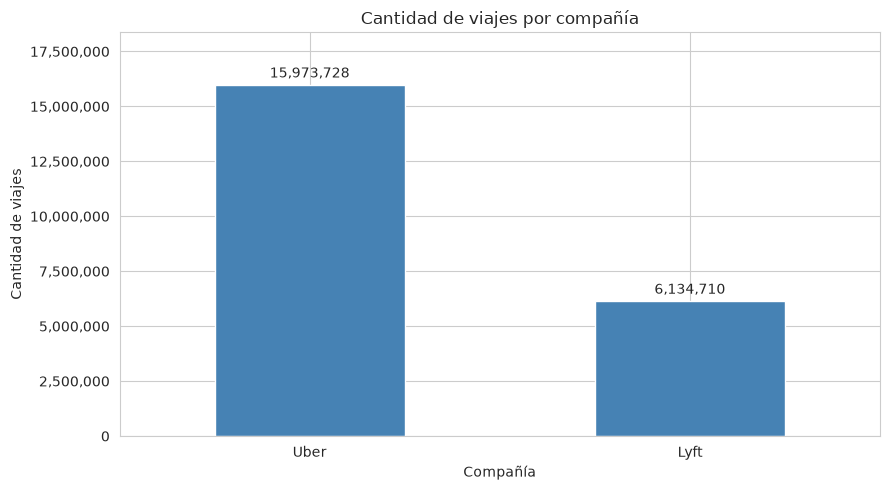

In [3]:
companias = {'HV0002': 'Juno', 'HV0003': 'Uber',
             'HV0004': 'Via', 'HV0005': 'Lyft'}

viajes = df['hvfhs_license_num'].map(companias).fillna(df['hvfhs_license_num']).value_counts()

ax = viajes.plot.bar(figsize=(9, 5), color='steelblue')

ax.bar_label(ax.containers[0], fmt='{:,.0f}', padding=3)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.set_ylim(0, viajes.max() * 1.15)

plt.title('Cantidad de viajes por compañía')
plt.xlabel('Compañía')
plt.ylabel('Cantidad de viajes')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

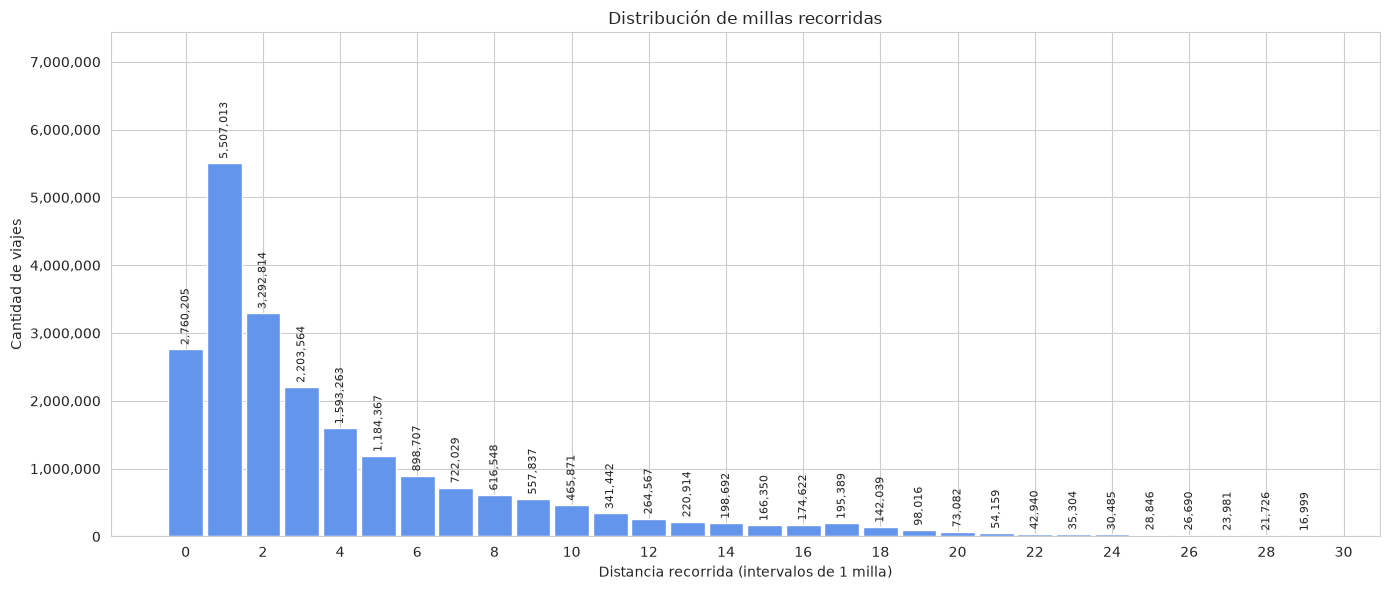

In [4]:
millas = df['trip_miles']
frecuencias, bins = np.histogram(millas.dropna(), bins=np.arange(0, 31, 1))

fig, ax = plt.subplots(figsize=(14, 6))
barras = ax.bar(bins[:-1], frecuencias, width=0.9, color='cornflowerblue')

ax.bar_label(barras, fmt='{:,.0f}', padding=3, rotation=90, fontsize=8)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.set_ylim(0, frecuencias.max() * 1.35)

plt.title('Distribución de millas recorridas')
plt.xlabel('Distancia recorrida (intervalos de 1 milla)')
plt.ylabel('Cantidad de viajes')
plt.xticks(np.arange(0, 31, 2))
plt.tight_layout()
plt.show()


In [5]:
viajes_cero = df[df['trip_miles'] == 0]

print(f"Viajes con 0 millas: {len(viajes_cero):,}")
print(f"Porcentaje: {len(viajes_cero) / len(df) * 100:.3f}%")

display(viajes_cero[[
    'trip_miles', 'trip_time',
    'base_passenger_fare', 'driver_pay',
    'PULocationID', 'DOLocationID'
]].head(10))

Viajes con 0 millas: 2,357
Porcentaje: 0.011%


,trip_miles,trip_time,base_passenger_fare,driver_pay,PULocationID,DOLocationID
10441,0.0,183,5.39,4.00,188,188
20822,0.0,145,7.61,4.00,138,138
21896,0.0,381,13.27,25.61,132,132
28791,0.0,473,7.76,5.19,178,178
42513,0.0,730,7.01,10.03,129,129
54414,0.0,241,10.79,5.45,203,203
72417,0.0,85,11.77,4.00,79,79
115193,0.0,58,48.05,31.50,162,162
119395,0.0,270,9.50,4.36,35,35
129218,0.0,125,12.09,6.48,230,230


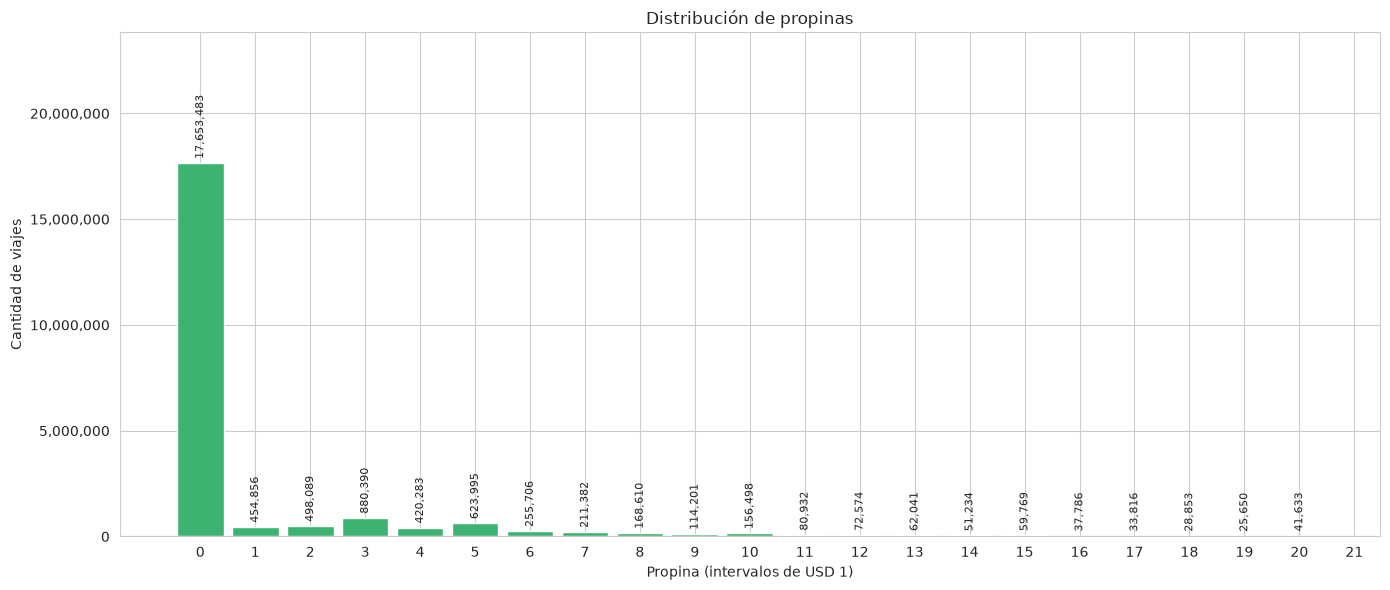

Viajes sin propina: 17,648,670
Porcentaje sin propina: 79.83%
Viajes representados: 21,931,781 de 22,108,438


In [6]:
propinas = df['tips']
frecuencias, bins = np.histogram(propinas.dropna(), bins=np.arange(0, 22, 1))

fig, ax = plt.subplots(figsize=(14, 6))
barras = ax.bar(bins[:-1], frecuencias, width=0.85, color='mediumseagreen')

ax.bar_label(barras, fmt='{:,.0f}', padding=3, rotation=90, fontsize=8)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.set_ylim(0, frecuencias.max() * 1.35)

plt.title('Distribución de propinas')
plt.xlabel('Propina (intervalos de USD 1)')
plt.ylabel('Cantidad de viajes')
plt.xticks(np.arange(0, 22, 1))
plt.tight_layout()
plt.show()

print(f'Viajes sin propina: {(propinas == 0).sum():,}')
print(f'Porcentaje sin propina: {(propinas == 0).mean() * 100:.2f}%')
print(f'Viajes representados: {frecuencias.sum():,} de {len(df):,}')

In [7]:
print(f"Propina máxima: ${df['tips'].max():,.2f}")
print(f"Propina mínima: ${df['tips'].min():,.2f}")

Propina máxima: $205.33
Propina mínima: $0.00


In [8]:
print(df['shared_match_flag'].value_counts(normalize=True) * 100)

shared_match_flag
N    98.939369
Y     1.060631
Name: proportion, dtype: float64
